In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!unzip /content/drive/MyDrive/Dataset/brats-2021-task1.zip -d /content/brats_data/


Archive:  /content/drive/MyDrive/Dataset/brats-2021-task1.zip.zip
  inflating: /content/brats_data/BraTS2021_00495.tar  
  inflating: /content/brats_data/BraTS2021_00621.tar  
  inflating: /content/brats_data/BraTS2021_Training_Data.tar  


In [ ]:
# Ekstrak file .tar yang ada di dalam ZIP pertama
!tar -xvf /content/brats_data/BraTS2021_Training_Data.tar -C /content/brats_data/

Streaming output truncated to the last 5000 lines.
./BraTS2021_00590/BraTS2021_00590_t1ce.nii.gz
./BraTS2021_00590/BraTS2021_00590_t2.nii.gz
./BraTS2021_00591/
./BraTS2021_00591/BraTS2021_00591_flair.nii.gz
./BraTS2021_00591/BraTS2021_00591_seg.nii.gz
./BraTS2021_00591/BraTS2021_00591_t1.nii.gz
./BraTS2021_00591/BraTS2021_00591_t1ce.nii.gz
./BraTS2021_00591/BraTS2021_00591_t2.nii.gz
./BraTS2021_00593/
./BraTS2021_00593/BraTS2021_00593_flair.nii.gz
./BraTS2021_00593/BraTS2021_00593_seg.nii.gz
./BraTS2021_00593/BraTS2021_00593_t1.nii.gz
./BraTS2021_00593/BraTS2021_00593_t1ce.nii.gz
./BraTS2021_00593/BraTS2021_00593_t2.nii.gz
./BraTS2021_00594/
./BraTS2021_00594/BraTS2021_00594_flair.nii.gz
./BraTS2021_00594/BraTS2021_00594_seg.nii.gz
./BraTS2021_00594/BraTS2021_00594_t1.nii.gz
./BraTS2021_00594/BraTS2021_00594_t1ce.nii.gz
./BraTS2021_00594/BraTS2021_00594_t2.nii.gz
./BraTS2021_00596/
./BraTS2021_00596/BraTS2021_00596_flair.nii.gz
./BraTS2021_00596/BraTS2021_00596_seg.nii.gz
./BraTS2021_0

In [ ]:
# Ekstrak file .tar lainnya jika ada
!tar -xvf /content/brats_data/BraTS2021_00495.tar -C /content/brats_data/
!tar -xvf /content/brats_data/BraTS2021_00621.tar -C /content/brats_data/



./
./BraTS2021_00495_flair.nii.gz
./BraTS2021_00495_seg.nii.gz
./BraTS2021_00495_t1.nii.gz
./BraTS2021_00495_t1ce.nii.gz
./BraTS2021_00495_t2.nii.gz
./
./BraTS2021_00621_flair.nii.gz
./BraTS2021_00621_seg.nii.gz
./BraTS2021_00621_t1.nii.gz
./BraTS2021_00621_t1ce.nii.gz
./BraTS2021_00621_t2.nii.gz


In [ ]:
!ls /content/brats_data/


BraTS2021_00000		      BraTS2021_01036
BraTS2021_00002		      BraTS2021_01037
BraTS2021_00003		      BraTS2021_01038
BraTS2021_00005		      BraTS2021_01039
BraTS2021_00006		      BraTS2021_01040
BraTS2021_00008		      BraTS2021_01041
BraTS2021_00009		      BraTS2021_01042
BraTS2021_00011		      BraTS2021_01043
BraTS2021_00012		      BraTS2021_01044
BraTS2021_00014		      BraTS2021_01045
BraTS2021_00016		      BraTS2021_01046
BraTS2021_00017		      BraTS2021_01047
BraTS2021_00018		      BraTS2021_01048
BraTS2021_00019		      BraTS2021_01049
BraTS2021_00020		      BraTS2021_01050
BraTS2021_00021		      BraTS2021_01051
BraTS2021_00022		      BraTS2021_01052
BraTS2021_00024		      BraTS2021_01053
BraTS2021_00025		      BraTS2021_01054
BraTS2021_00026		      BraTS2021_01055
BraTS2021_00028		      BraTS2021_01056
BraTS2021_00030		      BraTS2021_01057
BraTS2021_00031		      BraTS2021_01058
BraTS2021_00032		      BraTS2021_01059
BraTS2021_00033		      BraTS2021_01060
BraTS2021_00035		      Br

In [ ]:
%%writefile preprocess_brats.py
# preprocess_brats.py
import os
import json  # Tambahkan ini untuk mengimpor modul json
import numpy as np
import nibabel as nib
from pathlib import Path
from skimage.transform import resize as sk_resize

EPS = 1e-6

# ================== OPSI HEMAT UKURAN & RESIZE (ENV) ==================
# Hemat ukuran file .npz:
SAVE_FP16 = os.environ.get("SAVE_FP16", "1").strip()  # "1" simpan image sebagai float16
DROP_DED  = os.environ.get("DROP_DED",  "0").strip()  # "1" hilangkan kanal ΔED

# Resize opsional:
# Pilih salah satu:
# - RESIZE_TO="D,H,W"   contoh: "160,160,128"
# - RESIZE_SCALE="0.8"  contoh: "0.8"
# Jika keduanya kosong -> tidak resize.
RESIZE_TO_STR    = os.environ.get("RESIZE_TO", "192,192,144").strip()
RESIZE_SCALE_STR = os.environ.get("RESIZE_SCALE", "").strip()
ROUND_TO_MULT    = int(os.environ.get("ROUND_TO_MULT", "8"))  # 0 = nonaktif
# ======================================================================

# ================== OPSI SPLIT (ENV) ==================
# Gunakan fixed split (train/val/test) atau k-fold?
USE_FIXED_SPLIT = os.environ.get("USE_FIXED_SPLIT", "1").strip()  # "1" fixed (default), "0" k-fold
TRAIN_PCT = int(os.environ.get("TRAIN_PCT", "20"))
VAL_PCT   = int(os.environ.get("VAL_PCT",   "10"))
TEST_PCT  = int(os.environ.get("TEST_PCT",  "70"))
KFOLD_K   = int(os.environ.get("KFOLD_K",   "5"))
SPLIT_SEED= int(os.environ.get("SPLIT_SEED","13"))
# ======================================================

def _parse_resize_to(s):
    if not s: return None
    parts = [p.strip() for p in s.split(",")]
    if len(parts) != 3:
        raise ValueError("RESIZE_TO harus format 'D,H,W' (mis. '160,160,128').")
    return tuple(int(v) for v in parts)

def _round_to_mult(x, m):
    if m <= 0: return int(x)
    return int(np.round(x / m) * m)

def _decide_target_shape(curr_dhw):
    """curr_dhw: (D,H,W) setelah crop; return target (D,H,W) atau None"""
    if RESIZE_TO_STR:
        tgt = _parse_resize_to(RESIZE_TO_STR)
    elif RESIZE_SCALE_STR:
        s = float(RESIZE_SCALE_STR)
        D,H,W = curr_dhw
        tgt = (int(np.round(D*s)), int(np.round(H*s)), int(np.round(W*s)))
    else:
        return None
    if ROUND_TO_MULT > 0:
        tgt = tuple(_round_to_mult(v, ROUND_TO_MULT) for v in tgt)
    return tgt

def _resize_image_chwd(img, out_shape):
    """
    img: (C,D,H,W) float32 -> bilinear + anti_aliasing
    out_shape: (D,H,W)
    """
    C,D,H,W = img.shape
    out = np.zeros((C, *out_shape), dtype=np.float32)
    for c in range(C):
        out[c] = sk_resize(
            img[c], out_shape, order=1, preserve_range=True, anti_aliasing=True
        ).astype(np.float32)
    return out

def _resize_label_dhw(lbl, out_shape):
    """
    lbl: (D,H,W) uint8/int -> nearest-neighbor (order=0)
    """
    return sk_resize(
        lbl, out_shape, order=0, preserve_range=True, anti_aliasing=False
    ).astype(lbl.dtype)

def _glob_any(case_dir: Path, patterns):
    out=[]
    for p in patterns:
        out += list(case_dir.glob(p))
    return out

# ---------- util IO ----------
def _find_modalities(case_dir: Path):
    # Pencarian untuk modalitas BraTS 2021
    flair = _glob_any(case_dir, ["*_flair.nii*", "*FLAIR*.nii*"])
    t1    = _glob_any(case_dir, ["*_t1.nii*", "*T1.nii*", "*T1_.nii*"])
    t1ce  = _glob_any(case_dir, ["*_t1ce.nii*", "*_t1gd.nii*", "*T1CE*.nii*", "*T1Gd*.nii*"])
    t2    = _glob_any(case_dir, ["*_t2.nii*", "*T2*.nii*"])

    # Label: seg, segmentation, Consensus — semuanya *.nii*
    seg   = _glob_any(case_dir, ["*_seg.nii*", "*segmentation*.nii*", "*Consensus*.nii*"])

    if all([flair, t1, t1ce, t2, seg]):
        return flair[0], t1[0], t1ce[0], t2[0], seg[0]

    # Format 0000..0003 + seg (terima .nii / .nii.gz)
    m0 = _glob_any(case_dir, ["*_0000.nii*"])  # FLAIR
    m1 = _glob_any(case_dir, ["*_0001.nii*"])  # T1
    m2 = _glob_any(case_dir, ["*_0002.nii*"])  # T1CE
    m3 = _glob_any(case_dir, ["*_0003.nii*"])  # T2
    seg = _glob_any(case_dir, ["*_seg.nii*", "*segmentation*.nii*", "*Consensus*.nii*"])
    if all([m0,m1,m2,m3,seg]):
        return m0[0], m1[0], m2[0], m3[0], seg[0]

    raise FileNotFoundError(f"Modalitas tidak lengkap di {case_dir}")

def load_nii(p):
    img = nib.load(str(p)); arr = img.get_fdata(dtype=np.float32)
    return arr, img.affine, img.header

# ---------- intensitas & fitur ----------
def robust_clip(img, mask, lo=0.5, hi=99.5):
    vals = img[mask>0]
    if vals.size==0: return img
    lo_v = np.percentile(vals, lo); hi_v = np.percentile(vals, hi)
    return np.clip(img, lo_v, hi_v)

def zscore(img, mask):
    m = img[mask>0]
    mu = m.mean() if m.size else 0.0
    sd = m.std() if m.size else 1.0
    return (img - mu)/(sd + EPS)

def make_delta_ce(t1ce_c, t1_c):  # ET
    return (t1ce_c - t1_c)/(t1ce_c + t1_c + EPS)

def make_delta_ed(flair_c, t2_c): # edema
    return (flair_c - t2_c)/(flair_c + t2_c + EPS)

def get_bbox(mask, margin=8):
    coords = np.array(np.nonzero(mask))
    if coords.shape[1]==0:
        D,H,W = mask.shape; return (0,D,0,H,0,W)
    z0,y0,x0 = coords.min(axis=1); z1,y1,x1 = coords.max(axis=1)+1
    z0 = max(0,z0-margin); y0=max(0,y0-margin); x0=max(0,x0-margin)
    z1 = min(mask.shape[0], z1+margin); y1=min(mask.shape[1], y1+margin); x1=min(mask.shape[2], x1+margin)
    return (z0,z1,y0,y1,x0,x1)

def process_case(case_dir: Path, out_dir: Path, add_delta_ed=True):
    flair_p, t1_p, t1ce_p, t2_p, seg_p = _find_modalities(case_dir)
    flair,_,_ = load_nii(flair_p); t1,_,_ = load_nii(t1_p)
    t1ce,_,_ = load_nii(t1ce_p);   t2,_,_ = load_nii(t2_p)
    seg,_,_  = load_nii(seg_p)

    brain = (flair>0)|(t1>0)|(t1ce>0)|(t2>0)

    flair_c = robust_clip(flair, brain); t1_c = robust_clip(t1, brain)
    t1ce_c  = robust_clip(t1ce, brain); t2_c = robust_clip(t2, brain)

    dce = make_delta_ce(t1ce_c, t1_c)            # ΔCE
    ded = make_delta_ed(flair_c, t2_c) if add_delta_ed else None  # ΔED

    flair_z = zscore(flair_c, brain); t1_z = zscore(t1_c, brain)
    t1ce_z  = zscore(t1ce_c, brain);  t2_z = zscore(t2_c, brain)

    # ==== susun kanal (opsi buang ΔED untuk hemat) ====
    chans = [t1_z, t1ce_z, t2_z, flair_z, dce]
    if (ded is not None) and (DROP_DED != "1"):
        chans.append(ded)
    img = np.stack(chans, axis=0).astype(np.float32)  # (C,D,H,W)
    lbl = seg.astype(np.uint8)  # {0,1,2,4}

    # Crop ke bbox
    bbox = get_bbox(brain.astype(np.uint8), margin=8)
    z0,z1,y0,y1,x0,x1 = bbox
    img = img[:, z0:z1, y0:y1, x0:x1]
    lbl = lbl[z0:z1, y0:y1, x0:x1]

    # ========== RESIZE (opsional) ==========
    target = _decide_target_shape(img.shape[1:])  # (D,H,W) atau None
    if target is not None and tuple(target) != tuple(img.shape[1:]):
        img = _resize_image_chwd(img, target)
        lbl = _resize_label_dhw(lbl, target)
    # ======================================

    out_dir.mkdir(parents=True, exist_ok=True)
    cid = case_dir.name

    # ==== simpan hemat ruang ====
    img_to_save = img.astype(np.float16) if SAVE_FP16 == "1" else img.astype(np.float32)
    lbl_to_save = lbl.astype(np.uint8)

    np.savez_compressed(
        out_dir / f"{cid}.npz",
        image=img_to_save,
        label=lbl_to_save,
        bbox=np.array(bbox),
        case_id=cid,
        meta=np.array([
            ("save_fp16", SAVE_FP16),
            ("drop_ded",  DROP_DED),
            ("resize_to", RESIZE_TO_STR),
            ("resize_scale", RESIZE_SCALE_STR),
            ("round_to_mult", str(ROUND_TO_MULT))
        ], dtype=object)
    )
    return cid

def process_root(raw_root, out_root, add_delta_ed=True):
    raw_root = Path(raw_root); out_root = Path(out_root)
    if not raw_root.exists(): raise FileNotFoundError(raw_root)

    # Rekursif: cari label pakai pola *.nii* (mencakup .nii & .nii.gz)
    label_patterns = ["*_seg.nii*", "*segmentation*.nii*", "*Consensus*.nii*"]
    seg_files = []
    for pat in label_patterns:
        seg_files += list(raw_root.rglob(pat))

    case_dirs = sorted({p.parent for p in seg_files})
    if not case_dirs:
        raise RuntimeError(
            f"Tidak ada kasus ditemukan di {raw_root}.\n"
            f"Cek kembali: struktur & ekstensi file (harus .nii atau .nii.gz)."
        )

    saved=[]
    for c in case_dirs:
        try:
            cid = process_case(c, out_root, add_delta_ed)
            print("[OK]", cid)
            saved.append(cid)
        except Exception as e:
            print("[SKIP]", c, e)
    return saved

def make_kfold_splits(ids, k=5, seed=13, out_path=None):
    import random
    rng = random.Random(seed); ids = ids[:]; rng.shuffle(ids)
    folds=[]
    for i in range(k):
        val = ids[i::k]; train = [x for x in ids if x not in val]
        folds.append({"train": train, "val": val})
    if out_path:
        with open(out_path, "w") as f: json.dump(folds, f, indent=2)
    return folds

def make_fixed_split(ids, train_pct=20, val_pct=10, test_pct=70, seed=13, out_path=None):
    """
    Bagi daftar case 'ids' menjadi train/val/test dengan persentase (%).
    Default: train 20, val 10, test 70.
    """
    assert train_pct + val_pct + test_pct == 100, "Persentase harus berjumlah 100"
    import random
    rng = random.Random(seed)
    ids = ids[:]
    rng.shuffle(ids)
    N = len(ids)
    n_train = int(round(N * train_pct / 100.0))
    n_val   = int(round(N * val_pct   / 100.0))
    n_test  = N - n_train - n_val
    if n_test < 0:
        n_test = 0
        overflow = n_train + n_val - N
        n_val = max(0, n_val - overflow)
        n_train = N - n_val
    train = ids[:n_train]
    val   = ids[n_train:n_train+n_val]
    test  = ids[n_train+n_val:]
    split = {"train": train, "val": val, "test": test}
    if out_path:
        with open(out_path, "w") as f:
            json.dump(split, f, indent=2)
    return split

if __name__=="__main__":
    RAW = os.environ.get("brats_data", "/content/brats_data")
    OUT = os.environ.get("BRATS_OUT", "/content/brats_processed")
    ids = process_root(RAW, OUT, add_delta_ed=True)

    if USE_FIXED_SPLIT == "1":
        make_fixed_split(
            ids,
            train_pct=TRAIN_PCT,
            val_pct=VAL_PCT,
            test_pct=TEST_PCT,
            seed=SPLIT_SEED,
            out_path=str(Path(OUT) / "splits_fixed.json")
        )
        print(f"[INFO] Fixed split disimpan ke {Path(OUT) / 'splits_fixed.json'} "
              f"(train={TRAIN_PCT}%, val={VAL_PCT}%, test={TEST_PCT}%)")
    else:
        make_kfold_splits(ids, k=KFOLD_K, out_path=str(Path(OUT)/"splits.json"))
        print(f"[INFO] K-fold splits (k={KFOLD_K}) disimpan ke {Path(OUT) / 'splits.json'}")


Writing preprocess_brats.py


In [ ]:
import os
os.environ["brats_data"] = "/content/brats_data"
os.environ["BRATS_OUT"] = "/content/brats_processed"

# Aktifkan fixed split 20/10/70
os.environ["USE_FIXED_SPLIT"] = "1"
os.environ["TRAIN_PCT"] = "20"
os.environ["VAL_PCT"]   = "10"
os.environ["TEST_PCT"]  = "70"

# (opsional) hemat ukuran
os.environ["SAVE_FP16"] = "1"
os.environ["DROP_DED"]  = "0"
os.environ["RESIZE_TO"] = "192,192,144"  # atau kosongkan untuk tanpa resize
os.environ["ROUND_TO_MULT"] = "8"

!python preprocess_brats.py
# Hasil split: /content/brats_processed/splits_fixed.json


[OK] brats_data
[OK] BraTS2021_00000
[OK] BraTS2021_00002
[OK] BraTS2021_00003
[OK] BraTS2021_00005
[OK] BraTS2021_00006
[OK] BraTS2021_00008
[OK] BraTS2021_00009
[OK] BraTS2021_00011
[OK] BraTS2021_00012
[OK] BraTS2021_00014
[OK] BraTS2021_00016
[OK] BraTS2021_00017
[OK] BraTS2021_00018
[OK] BraTS2021_00019
[OK] BraTS2021_00020
[OK] BraTS2021_00021
[OK] BraTS2021_00022
[OK] BraTS2021_00024
[OK] BraTS2021_00025
[OK] BraTS2021_00026
[OK] BraTS2021_00028
[OK] BraTS2021_00030
[OK] BraTS2021_00031
[OK] BraTS2021_00032
[OK] BraTS2021_00033
[OK] BraTS2021_00035
[OK] BraTS2021_00036
[OK] BraTS2021_00043
[OK] BraTS2021_00044
[OK] BraTS2021_00045
[OK] BraTS2021_00046
[OK] BraTS2021_00048
[OK] BraTS2021_00049
[OK] BraTS2021_00051
[OK] BraTS2021_00052
[OK] BraTS2021_00053
[OK] BraTS2021_00054
[OK] BraTS2021_00056
[OK] BraTS2021_00058
[OK] BraTS2021_00059
[OK] BraTS2021_00060
[OK] BraTS2021_00061
[OK] BraTS2021_00062
[OK] BraTS2021_00063
[OK] BraTS2021_00064
[OK] BraTS2021_00066
[OK] BraTS2021_000

In [ ]:
%%writefile brats_dataset.py
import os, json, random, numpy as np, torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

def map_0123(lbl):  # {0,1,2,4} → {0,1,2,3}
    out = lbl.copy(); out[out==4]=3; return out

def random_bias_field(img, alpha=0.05):
    C,D,H,W = img.shape
    zz=np.linspace(-1,1,D)[:,None,None]; yy=np.linspace(-1,1,H)[None,:,None]; xx=np.linspace(-1,1,W)[None,None,:]
    field = 1.0 + alpha*(zz+yy+xx)
    return img*field

def random_gamma(img, gamma=(0.9, 1.1), eps=1e-6):
    """
    Aman-NaN, per-channel:
    - bersihkan NaN/Inf
    - min-max normalize → power → rescale balik
    """
    g = random.uniform(*gamma)
    img = img.astype(np.float32, copy=False)
    img = np.nan_to_num(img, nan=0.0, posinf=0.0, neginf=0.0)

    C = img.shape[0]
    out = img.copy()
    for c in range(C):
        vmin = np.min(out[c]); vmax = np.max(out[c])
        if not np.isfinite(vmin) or not np.isfinite(vmax) or (vmax - vmin) < eps:
            continue
        norm = (out[c] - vmin) / (vmax - vmin + eps)
        norm = np.clip(norm, 0.0, 1.0)
        norm = np.power(norm, g)
        out[c] = norm * (vmax - vmin) + vmin
    return out

def random_flip(img, lbl):
    for ax in [1,2,3]:
        if random.random()<0.5:
            img=np.flip(img,axis=ax); lbl=np.flip(lbl,axis=ax-1)
    return img, lbl

def fg_vox(lbl):
    idx = np.argwhere(lbl>0)
    return idx if idx.size else [(0,0,0)]

def sample_patch(img, lbl, size=(128,128,128), force_fg=False, tries=50):
    C,D,H,W=img.shape; dz,dy,dx=size
    for _ in range(tries):
        if force_fg and (lbl>0).any():
            z,y,x = random.choice(fg_vox(lbl))
            z0=max(0,z-dz//2); y0=max(0,y-dy//2); x0=max(0,x-dx//2)
        else:
            z0=random.randint(0,max(0,D-dz)) if D>dz else 0
            y0=random.randint(0,max(0,H-dy)) if H>dy else 0
            x0=random.randint(0,max(0,W-dx)) if W>dx else 0
        z1,y1,x1=z0+dz,y0+dy,x0+dx
        if z1<=D and y1<=H and x1<=W:
            ip=img[:,z0:z1,y0:y1,x0:x1]; lp=lbl[z0:z1,y0:y1,x0:x1]
            if (not force_fg) or (lp>0).any(): return ip,lp
    # fallback center
    z0=max(0,(D-dz)//2); y0=max(0,(H-dy)//2); x0=max(0,(W-dx)//2)
    return img[:,z0:z0+dz,y0:y0+dy,x0:x0+dx], lbl[z0:z0+dz,y0:y0+dy,x0:x0+dx]

def pad_to_divisible(img, lbl, factor=32):
    # img: (C, D, H, W), lbl: (D, H, W)
    C, D, H, W = img.shape
    pad_d = (factor - D % factor) % factor
    pad_h = (factor - H % factor) % factor
    pad_w = (factor - W % factor) % factor

    img_padded = F.pad(torch.from_numpy(img), (0, pad_w, 0, pad_h, 0, pad_d), mode='constant', value=0)
    lbl_padded = F.pad(torch.from_numpy(lbl).unsqueeze(0), (0, pad_w, 0, pad_h, 0, pad_d), mode='constant', value=0).squeeze(0)

    return img_padded.numpy(), lbl_padded.numpy()

def _resolve_fold(folds_obj, fold_idx):
    """
    Mengembalikan dict {"train":[...], "val":[...]} dari berbagai bentuk JSON.
    """
    # bentuk 1: {"folds":[{train, val}, ...]}
    if isinstance(folds_obj, dict) and "folds" in folds_obj and isinstance(folds_obj["folds"], list):
        folds_list = folds_obj["folds"]
        if fold_idx < 0 or fold_idx >= len(folds_list):
            raise KeyError(f"Fold index {fold_idx} out of range (0..{len(folds_list)-1}).")
        return folds_list[fold_idx]

    # bentuk 2: list of folds: [{train, val}, ...]
    if isinstance(folds_obj, list):
        if fold_idx < 0 or fold_idx >= len(folds_obj):
            raise KeyError(f"Fold index {fold_idx} out of range (0..{len(folds_obj)-1}).")
        return folds_obj[fold_idx]

    # bentuk 3: dict dengan kunci string angka: {"0":{train,val}, "1":{...}}
    if isinstance(folds_obj, dict):
        if str(fold_idx) in folds_obj:
            return folds_obj[str(fold_idx)]
        if fold_idx in folds_obj:
            return folds_obj[fold_idx]
        # bentuk 4: single split {"train":[...], "val":[...]}
        if "train" in folds_obj and "val" in folds_obj:
            if fold_idx not in (0, "0"):
                print(f"[WARN] File split hanya punya 1 fold. Memakai fold 0 meskipun diminta {fold_idx}.")
            return folds_obj

    # jika tidak cocok apa pun
    raise KeyError(
        f"Tidak dapat menemukan fold {fold_idx}. Kunci tersedia: "
        f"{list(folds_obj.keys()) if isinstance(folds_obj, dict) else f'len={len(folds_obj)} (list)'}.\n"
        f"Format yang didukung: "
        f'1) {{"0":{{"train":[...],"val":[...]}}, ...}}, '
        f'2) [{{"train":[...],"val":[...]}}, ...], '
        f'3) {{"folds":[{{"train":[...],"val":[...]}}, ...]}}, '
        f'4) single {{"train":[...],"val":[...]}}.'
    )

class BraTSPatchDS(Dataset):
    def __init__(self, root, splits_fixed_json, fold=0, train=True, patch=128, fg_ratio=0.5, augment=True):
        with open(splits_fixed_json,"r") as f:
            folds = json.load(f)

        fold_dict = _resolve_fold(folds, fold)
        try:
            ids = fold_dict["train"] if train else fold_dict["val"]
        except KeyError as e:
            raise KeyError(f"Key {e} tidak ditemukan di fold. Pastikan ada 'train' dan 'val'. Contoh: "
                           f'{{"train":["ID1","ID2"], "val":["ID3"]}}')

        self.paths=[os.path.join(root,f"{cid}.npz") for cid in ids]
        self.patch=(patch,patch,patch); self.fg_ratio=fg_ratio; self.train=train; self.augment=augment

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        d = np.load(self.paths[i])
        img = d["image"].astype(np.float32)
        lbl = d["label"].astype(np.uint8)
        lbl = map_0123(lbl)

        # Bersihkan NaN/Inf sejak awal
        img = np.nan_to_num(img, nan=0.0, posinf=0.0, neginf=0.0)

        ip, lp = sample_patch(img, lbl, self.patch, force_fg=(np.random.rand() < self.fg_ratio))
        ip, lp = pad_to_divisible(ip, lp, factor=32)

        if self.train and self.augment:
            if np.random.rand() < 0.5:
                ip = random_bias_field(ip, 0.05)
            if np.random.rand() < 0.5:
                ip[:4] = random_gamma(ip[:4], (0.9, 1.1))  # range dipersempit agar stabil
            if np.random.rand() < 0.5:
                ip = ip + np.random.normal(0, 0.01, size=ip.shape).astype(np.float32)
            ip, lp = random_flip(ip, lp)

        # Pastikan patch final bebas NaN/Inf
        ip = np.nan_to_num(ip, nan=0.0, posinf=0.0, neginf=0.0)

        return torch.from_numpy(ip.copy()), torch.from_numpy(lp.astype(np.int64))

def make_loader(root, splits_fixed, fold=0, train=True, bs=1, nw=2, patch=128, pin_mem=None):
    if pin_mem is None:
        pin_mem = torch.cuda.is_available()
    ds = BraTSPatchDS(root, splits_fixed, fold, train, patch=patch)
    return DataLoader(
        ds,
        batch_size=bs,
        shuffle=train,
        num_workers=nw,
        pin_memory=pin_mem
    )


Writing brats_dataset.py


In [ ]:
%%writefile lightunet_transformer3d.py
import torch, math
import torch.nn as nn
import torch.nn.functional as F

# ----- building blocks -----
class DWConv3d(nn.Module):
    def __init__(self, c, k=3, s=1, p=1):
        super().__init__()
        self.dw = nn.Conv3d(c, c, k, s, p, groups=c, bias=False)
        self.pw = nn.Conv3d(c, c, 1, 1, 0, bias=False)
        self.bn = nn.InstanceNorm3d(c)
        self.act= nn.LeakyReLU(0.1, inplace=True)
    def forward(self,x):
        x = self.dw(x); x=self.pw(x); x=self.bn(x); return self.act(x)

class InvertedResidual3D(nn.Module):
    def __init__(self, cin, cout, exp=2, s=1):
        super().__init__()
        mid = int(cin*exp)
        self.use_res = (s==1 and cin==cout)
        self.conv = nn.Sequential(
            nn.Conv3d(cin, mid, 1, 1, 0, bias=False),
            nn.InstanceNorm3d(mid), nn.LeakyReLU(0.1,True),
            nn.Conv3d(mid, mid, 3, s, 1, groups=mid, bias=False),
            nn.InstanceNorm3d(mid), nn.LeakyReLU(0.1,True),
            nn.Conv3d(mid, cout, 1, 1, 0, bias=False),
            nn.InstanceNorm3d(cout)
        )
    def forward(self,x):
        out=self.conv(x)
        if self.use_res: out = out + x
        return F.leaky_relu(out,0.1,inplace=True)

# ----- windowed attention 3D (hemat) -----
def window_partition(x, win_size):  # x: B,C,D,H,W
    B,C,D,H,W = x.shape
    wd,wh,ww = win_size
    x = x.view(B, C, D//wd, wd, H//wh, wh, W//ww, ww)
    x = x.permute(0,2,4,6,3,5,7,1).contiguous()  # B, nD, nH, nW, wd, wh, ww, C
    windows = x.view(-1, wd*wh*ww, C)            # (B*nW, tokens, C)
    return windows, (B,D,H,W)

def window_unpartition(windows, win_size, orig_shape):
    B,D,H,W = orig_shape
    wd,wh,ww = win_size
    nD, nH, nW = D//wd, H//wh, W//ww
    x = windows.view(B, nD, nH, nW, wd, wh, ww, -1)  # B, nD,nH,nW, wd,wh,ww, C
    x = x.permute(0,7,1,4,2,5,3,6).contiguous()      # B,C,nD,wd,nH,wh,nW,ww
    x = x.view(B, -1, D, H, W)
    return x

class MLP(nn.Module):
    def __init__(self, dim, ratio=2):
        super().__init__()
        hidden=int(dim*ratio)
        self.fc1=nn.Conv3d(dim,hidden,1)
        self.act=nn.GELU()
        self.fc2=nn.Conv3d(hidden,dim,1)
    def forward(self,x): return self.fc2(self.act(self.fc1(x)))

class WindowAttention3D(nn.Module):
    def __init__(self, dim, num_heads=4, win_size=(8,8,8), drop=0.0):
        super().__init__()
        self.dim=dim; self.num_heads=num_heads; self.win_size=win_size
        self.scale = (dim//num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim*3, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)
        self.attn_drop = nn.Dropout(drop)
    def forward(self, x):  # x: B,C,D,H,W
        windows, shape = window_partition(x, self.win_size)  # (B*nW, T, C)
        Bn, T, C = windows.shape
        qkv = self.qkv(windows).reshape(Bn, T, 3, self.num_heads, C//self.num_heads)
        q, k, v = qkv[:,:,0], qkv[:,:,1], qkv[:,:,2]  # (Bn, T, heads, ch)
        q = q.permute(0,2,1,3); k = k.permute(0,2,1,3); v = v.permute(0,2,1,3)  # (Bn, heads, T, ch)
        attn = (q @ k.transpose(-2,-1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)
        out = attn @ v  # (Bn, heads, T, ch)
        out = out.permute(0,2,1,3).reshape(Bn, T, C)
        out = self.proj(out)  # (Bn, T, C)
        out = out.view(Bn, T, C)
        out = window_unpartition(out, self.win_size, shape)  # back to B,C,D,H,W
        return out

class TransformerBlock3D(nn.Module):
    def __init__(self, dim, heads=4, win=(8,8,8), mlp_ratio=2.0, drop=0.0, sd=0.0):
        super().__init__()
        self.norm1=nn.InstanceNorm3d(dim, affine=True)
        self.attn = WindowAttention3D(dim, heads, win, drop)
        self.drop1=nn.Dropout3d(sd)
        self.norm2=nn.InstanceNorm3d(dim, affine=True)
        self.mlp  = MLP(dim, mlp_ratio)
        self.drop2=nn.Dropout3d(sd)
    def forward(self,x):
        x = x + self.drop1(self.attn(self.norm1(x)))
        x = x + self.drop2(self.mlp(self.norm2(x)))
        return x

# ----- Lightweight U-Net + transformer -----
class LightUNetTrans3D(nn.Module):
    def __init__(self, in_ch=6, n_cls=4, base=32, win=(8,8,8)):
        super().__init__()
        c1, c2, c3, c4 = base, base*2, base*3, base*4

        # Encoder
        self.stem = nn.Sequential(
            nn.Conv3d(in_ch, c1, 3, padding=1, bias=False), nn.InstanceNorm3d(c1), nn.LeakyReLU(0.1,True),
            DWConv3d(c1)
        )
        self.enc2 = InvertedResidual3D(c1, c2, exp=2, s=2)   # 1/2
        self.enc3 = InvertedResidual3D(c2, c3, exp=2, s=2)   # 1/4
        self.enc4 = InvertedResidual3D(c3, c4, exp=2, s=2)   # 1/8

        # Transformer blocks di resolusi menengah (hemat)
        self.tr3  = TransformerBlock3D(c3, heads=4, win=win, mlp_ratio=2.0, sd=0.05)
        self.tr4  = TransformerBlock3D(c4, heads=4, win=win, mlp_ratio=2.0, sd=0.05)

        # Decoder
        self.up3  = nn.ConvTranspose3d(c4, c3, 2, stride=2)
        self.dec3 = nn.Sequential(nn.Conv3d(c3+c3, c3, 3, padding=1, bias=False), nn.InstanceNorm3d(c3), nn.LeakyReLU(0.1,True))
        self.up2  = nn.ConvTranspose3d(c3, c2, 2, stride=2)
        self.dec2 = nn.Sequential(nn.Conv3d(c2+c2, c2, 3, padding=1, bias=False), nn.InstanceNorm3d(c2), nn.LeakyReLU(0.1,True))
        self.up1  = nn.ConvTranspose3d(c2, c1, 2, stride=2)
        self.dec1 = nn.Sequential(nn.Conv3d(c1+c1, c1, 3, padding=1, bias=False), nn.InstanceNorm3d(c1), nn.LeakyReLU(0.1,True))
        self.head = nn.Conv3d(c1, n_cls, 1)

    def forward(self,x):
        e1 = self.stem(x)         # B,c1,D,H,W
        e2 = self.enc2(e1)        # 1/2
        e3 = self.enc3(e2)        # 1/4
        e3t= self.tr3(e3)
        e4 = self.enc4(e3t)       # 1/8
        e4t= self.tr4(e4)

        d3 = self.up3(e4t)
        d3 = self.dec3(torch.cat([d3, e3t],1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2],1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1],1))
        return self.head(d1)


Writing lightunet_transformer3d.py


In [ ]:
# TULIS ULANG file yang benar
%%writefile /content/metrics_flops.py
import os, numpy as np, torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

# --------- core metrics ----------
def one_hot(labels, num_classes):
    return torch.nn.functional.one_hot(labels, num_classes).permute(0,4,1,2,3).float()

def dice_per_class(logits, target, eps=1e-6):
    C = logits.shape[1]
    probs = torch.softmax(logits, dim=1)
    tgt = one_hot(target, C).to(probs.device)
    dims=(0,2,3,4)
    inter=torch.sum(probs*tgt, dims)
    denom=torch.sum(probs, dims)+torch.sum(tgt,dims)+eps
    return (2*inter)/denom  # (C,)

def iou_per_class(logits, target, eps=1e-6):
    preds = torch.argmax(logits, dim=1)
    C = logits.shape[1]; ious=[]
    for c in range(C):
        p=(preds==c); t=(target==c)
        inter=(p&t).sum().float()
        union=(p|t).sum().float()+eps
        ious.append((inter/union).item())
    return torch.tensor(ious)

def dice_et_tc_wt(logits, target, eps=1e-6):
    preds=torch.argmax(logits,dim=1)
    masks=[lambda x: x==3, lambda x:(x==1)|(x==3), lambda x:(x==1)|(x==2)|(x==3)]
    out=[]
    for fn in masks:
        p=fn(preds); t=fn(target)
        inter=(p&t).sum().float()*2
        denom=p.sum().float()+t.sum().float()+eps
        out.append((inter/denom).item())
    return out  # [ET,TC,WT]

# --------- FLOPs estimator (approx, MAC->FLOPs x2) ----------
def count_flops(model, input_shape=(1,6,128,128,128)):
    macs=[]
    def conv_hook(m, inp, out):
        cin=m.in_channels; cout=m.out_channels
        kd,kh,kw = m.kernel_size if isinstance(m.kernel_size,tuple) else (m.kernel_size,)*3
        B,C,D,H,W = out.shape
        macs.append(B*D*H*W*(cin//m.groups)*cout*kd*kh*kw)
    def linear_hook(m,inp,out):
        in_f=m.in_features; out_f=m.out_features
        N = out.numel()//out_f
        macs.append(N*in_f*out_f)
    hooks=[]
    for mod in model.modules():
        if isinstance(mod, torch.nn.Conv3d): hooks.append(mod.register_forward_hook(conv_hook))
        if isinstance(mod, torch.nn.Linear): hooks.append(mod.register_forward_hook(linear_hook))
    x=torch.randn(*input_shape).to(next(model.parameters()).device)
    with torch.no_grad(): _=model(x)
    for h in hooks: h.remove()
    return sum(macs)*2/1e9  # GFLOPs

# --------- plotting utilities ----------
def ensure_dir(p): os.makedirs(p, exist_ok=True); return p

def plot_train_curves(train_losses, val_losses=None, out_png="train_loss.png"):
    plt.figure()
    plt.plot(train_losses, label="train")
    if val_losses and len(val_losses)>0: plt.plot(val_losses, label="val")
    plt.xlabel("iteration"); plt.ylabel("loss"); plt.title("Training/Validation Loss")
    if val_losses and len(val_losses)>0: plt.legend()
    plt.tight_layout(); plt.savefig(out_png, dpi=200); plt.close()

def plot_confusion_matrix(cm, class_names, out_png="cm.png"):
    plt.figure()
    plt.imshow(cm, interpolation="nearest")
    plt.title("Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("True")
    ticks=range(len(class_names))
    plt.xticks(ticks, class_names, rotation=45, ha="right"); plt.yticks(ticks, class_names)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j,i,int(cm[i,j]), ha="center", va="center")
    plt.tight_layout(); plt.savefig(out_png, dpi=200); plt.close()

def plot_roc_curves(fprs, tprs, aucs, class_names, out_png="roc.png"):
    plt.figure()
    for c in range(len(class_names)):
        plt.plot(fprs[c], tprs[c], label=f"{class_names[c]} (AUC={aucs[c]:.3f})")
    plt.plot([0,1],[0,1],"--")
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC Curves"); plt.legend()
    plt.tight_layout(); plt.savefig(out_png, dpi=200); plt.close()

def plot_pr_curves(precs, recs, aucs, class_names, out_png="pr.png"):
    plt.figure()
    for c in range(len(class_names)):
        plt.plot(recs[c], precs[c], label=f"{class_names[c]} (AUC={aucs[c]:.3f})")
    plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("PR Curves"); plt.legend()
    plt.tight_layout(); plt.savefig(out_png, dpi=200); plt.close()


Writing /content/metrics_flops.py


In [ ]:
%%writefile train_lightunet_trans.py
import os, numpy as np, torch
from torch import nn, optim
from brats_dataset import make_loader
from lightunet_transformer3d import LightUNetTrans3D
from metrics_flops import (
    dice_per_class, iou_per_class, dice_et_tc_wt, count_flops,
    ensure_dir, plot_train_curves, plot_confusion_matrix,
    plot_roc_curves, plot_pr_curves
)
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

# ==== Konfigurasi ====
PROC_ROOT = "/content/brats_processed"
SPLITS    = os.path.join(PROC_ROOT, "splits_fixed.json")
FOLD      = 0
PATCH_SIZE= 64
BATCH     = 1
USE_DELTA_ED = True
IN_CH     = 6 if USE_DELTA_ED else 5
BASE_C    = 32
WIN       = (8,8,8)
EPOCHS    = 15          # ganti 100–300 untuk training serius

# ==== Device & DataLoader ====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_type = "cuda" if torch.cuda.is_available() else "cpu"   # <-- penting untuk torch.amp
use_cuda = torch.cuda.is_available()
if use_cuda:
    torch.backends.cudnn.benchmark = True

train_loader = make_loader(PROC_ROOT, SPLITS, fold=FOLD, train=True,  bs=BATCH, nw=2, patch=PATCH_SIZE, pin_mem=use_cuda)
val_loader   = make_loader(PROC_ROOT, SPLITS, fold=FOLD, train=False, bs=1,     nw=2, patch=PATCH_SIZE, pin_mem=use_cuda)

# ==== Model, Optim, Loss, AMP ====
model = LightUNetTrans3D(in_ch=IN_CH, n_cls=4, base=BASE_C, win=WIN).to(device)
opt   = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
ce    = nn.CrossEntropyLoss()
# Migrasi GradScaler → API baru
scaler = torch.amp.GradScaler(device_type, enabled=(device_type == "cuda"))

def dice_loss(logits, target, eps=1e-6):
    C = logits.shape[1]
    probs = torch.softmax(logits, dim=1)
    tgt = torch.nn.functional.one_hot(target, num_classes=C).permute(0,4,1,2,3).float()
    dims=(0,2,3,4)
    inter=torch.sum(probs*tgt, dims)
    denom=torch.sum(probs, dims)+torch.sum(tgt,dims)+eps
    return 1.0 - (2*inter/denom).mean()

train_loss_hist=[]; val_loss_hist=[]

def train_one_epoch(epoch=0):
    model.train()
    for step,(x,y) in enumerate(train_loader):
        x,y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type, enabled=(device_type == "cuda")):
            logits = model(x.float())
            logits = torch.nan_to_num(logits, nan=0.0, posinf=1e4, neginf=-1e4)
            loss = ce(logits, y) + dice_loss(logits, y)

        # Guard: skip step bila loss non-finite (hindari NaN memapar scaler)
        if not torch.isfinite(loss):
            print(f"[WARN] non-finite loss @ epoch {epoch} step {step}: {loss.item()}. Skipping step.")
            scaler.update()
            continue

        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        train_loss_hist.append(loss.item())
        if step % 10 == 0:
            print(f"epoch {epoch} step {step} | loss {loss.item():.4f}")

@torch.no_grad()
def validate_full(return_curves=True):
    model.eval()
    dices=[]; ious=[]; et_tc_wt=[]
    cm_accum = np.zeros((4,4), dtype=np.int64)
    yscore_per_class=[[] for _ in range(4)]
    ytrue_per_class =[[] for _ in range(4)]
    val_losses=[]
    for x,y in val_loader:
        x,y = x.to(device), y.to(device)
        logits = model(x.float())
        logits = torch.nan_to_num(logits, nan=0.0, posinf=1e4, neginf=-1e4)  # sanitasi juga di validasi

        # loss val
        val_losses.append( (ce(logits,y) + dice_loss(logits,y)).item() )
        # dice/iou/et-tc-wt
        dices.append(dice_per_class(logits,y).cpu().numpy())
        ious.append(iou_per_class(logits,y).cpu().numpy())
        et_tc_wt.append(np.array(dice_et_tc_wt(logits,y)))
        # confusion matrix
        pred = torch.argmax(logits, dim=1).cpu().numpy().ravel()
        true = y.cpu().numpy().ravel()
        cm_accum += confusion_matrix(true, pred, labels=[0,1,2,3])
        if return_curves:
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probs = np.nan_to_num(probs, nan=0.0, posinf=0.0, neginf=0.0)
            B,C,D,H,W = probs.shape
            probs = probs.reshape(B,C,-1)
            y_flat = y.cpu().numpy().reshape(B,-1)
            for c in range(4):
                ytrue_per_class[c].append( (y_flat==c).astype(np.uint8) )
                yscore_per_class[c].append( probs[:,c,:] )
    dices=np.mean(np.stack(dices),0)
    ious =np.mean(np.stack(ious),0)
    et_tc_wt=np.mean(np.stack(et_tc_wt),0)
    val_loss_mean=float(np.mean(val_losses)) if len(val_losses)>0 else None

    results = {
        "dice_per_class": dices,
        "iou_per_class":  ious,
        "dice_et_tc_wt":  et_tc_wt,
        "val_loss_mean":  val_loss_mean,
        "cm": cm_accum
    }
    if return_curves:
        fprs=[]; tprs=[]; aucs_roc=[]; precs=[]; recs=[]; aucs_pr=[]
        for c in range(4):
            y_true = np.concatenate(ytrue_per_class[c], axis=None)
            y_scr  = np.concatenate(yscore_per_class[c], axis=None)
            if y_true.max()==y_true.min():
                fprs.append(np.array([0,1])); tprs.append(np.array([0,1])); aucs_roc.append(0.0)
                recs.append(np.array([0,1])); precs.append(np.array([1,0])); aucs_pr.append(0.0)
            else:
                y_scr = np.nan_to_num(y_scr, nan=0.0, posinf=0.0, neginf=0.0)
                fpr,tpr,_ = roc_curve(y_true, y_scr)
                pr,rc,_   = precision_recall_curve(y_true, y_scr)
                fprs.append(fpr); tprs.append(tpr); aucs_roc.append(auc(fpr,tpr))
                precs.append(pr); recs.append(rc);  aucs_pr.append(auc(rc,pr))
        results.update({"fprs":fprs,"tprs":tprs,"aucs_roc":aucs_roc,"precs":precs,"recs":recs,"aucs_pr":aucs_pr})
    return results

def main():
    # Pastikan folder figs selalu ada, bahkan jika training berhenti dini
    ensure_dir("/content/figs")

    gflops = count_flops(model, input_shape=(1,IN_CH,PATCH_SIZE,PATCH_SIZE,PATCH_SIZE))
    print(f"Approx GFLOPs @ patch {PATCH_SIZE}³: {gflops:.2f} GFLOPs")

    for ep in range(EPOCHS):
        train_one_epoch(ep)
        val_res = validate_full(True)
        if val_res["val_loss_mean"] is not None:
            val_loss_hist.append(val_res["val_loss_mean"])

    print("Val Dice per-class [BG,NCR/NET,ED,ET]:", np.round(val_res["dice_per_class"],4))
    print("Val IoU  per-class [BG,NCR/NET,ED,ET]:", np.round(val_res["iou_per_class"],4))
    print("Val Dice [ET,TC,WT]:", np.round(val_res["dice_et_tc_wt"],4))

    plot_train_curves(train_loss_hist, val_loss_hist, out_png="/content/figs/train_loss.png")
    CLASS_NAMES=["BG","NCR/NET","ED","ET"]
    plot_confusion_matrix(val_res["cm"], CLASS_NAMES, out_png="/content/figs/cm.png")
    plot_roc_curves(val_res["fprs"], val_res["tprs"], val_res["aucs_roc"], CLASS_NAMES, out_png="/content/figs/roc.png")
    plot_pr_curves(val_res["precs"], val_res["recs"], val_res["aucs_pr"], CLASS_NAMES, out_png="/content/figs/pr.png")
    print("Saved plots in /content/figs")

if __name__=="__main__":
    main()


Writing train_lightunet_trans.py


In [ ]:
!python train_lightunet_trans.py
!ls -lah /content/figs


Approx GFLOPs @ patch 64³: 54.38 GFLOPs
epoch 0 step 0 | loss 2.3759
epoch 0 step 10 | loss 1.8191
epoch 0 step 20 | loss 1.8928
epoch 0 step 30 | loss 1.6573
epoch 0 step 40 | loss 1.7083
epoch 0 step 50 | loss 1.5602
epoch 0 step 60 | loss 1.1670
epoch 0 step 70 | loss 1.6140
epoch 0 step 80 | loss 1.5235
epoch 0 step 90 | loss 1.2290
epoch 0 step 100 | loss 1.0397
epoch 0 step 110 | loss 1.1069
epoch 0 step 120 | loss 1.1724
epoch 0 step 130 | loss 1.0850
epoch 0 step 140 | loss 1.3000
epoch 0 step 150 | loss 1.4376
epoch 0 step 160 | loss 1.0204
epoch 0 step 170 | loss 1.0178
epoch 0 step 180 | loss 1.0614
epoch 0 step 190 | loss 0.9912
epoch 0 step 200 | loss 0.8945
epoch 0 step 210 | loss 0.8740
epoch 0 step 220 | loss 0.8884
epoch 0 step 230 | loss 0.6944
epoch 0 step 240 | loss 0.6666
epoch 1 step 0 | loss 0.5593
epoch 1 step 10 | loss 0.9352
epoch 1 step 20 | loss 0.7112
epoch 1 step 30 | loss 1.3102
epoch 1 step 40 | loss 1.1483
epoch 1 step 50 | loss 0.6877
epoch 1 step 60 |

In [ ]:
!export BRATS2021_OUT=/content/brats_processed
!export WEIGHTS=/content/checkpoints/best.pt

In [ ]:
# === Colab setup (opsional jika belum ada) ===
!pip -q install scipy

import os
# -- UBAH path ini ke lokasi NPZ kamu --
os.environ["BRATS2021_OUT"] = "/content/brats_processed"  # contoh
# (opsional) set checkpoint kalau punya bobot terlatih
# os.environ["WEIGHTS"] = "/content/checkpoints/best.pt"

# folder output
OUT_PNG = "/content/brats2021_training_process.png"


In [ ]:
import os, glob, numpy as np, matplotlib.pyplot as plt

# post-process ops
from scipy.ndimage import label as cc_label, binary_closing, binary_fill_holes, generate_binary_structure

# ====== cari dataset ======
def find_npz_2021():
    candidates = [
        os.environ.get("BRATS2021_OUT", ""),
        os.environ.get("BRATS_OUT", ""),
        "/content/brats2021_processed",
        "/content/brats_processed",
        "/mnt/data/brats2021_processed",
        "/mnt/data/brats_processed",
    ]
    for root in candidates:
        if not root:
            continue
        paths = sorted(glob.glob(os.path.join(root, "*.npz")))
        if len(paths) > 0:
            return root, paths
    return None, []

COLOR_NCR  = np.array([0.2, 0.4, 1.0])  # biru
COLOR_ED   = np.array([0.2, 1.0, 0.2])  # hijau
COLOR_ET   = np.array([1.0, 0.2, 0.2])  # merah
ALPHA      = 0.35

def norm01(x):
    x = x.astype(np.float32)
    return (x - x.min()) / (x.max() - x.min() + 1e-6)

def to_rgb_overlay(bg, masks):
    """bg: (H,W) 0..1, masks: [(mask_bool, color_rgb), ...]"""
    rgb = np.stack([bg, bg, bg], axis=-1).copy()
    for m, color in masks:
        m = m.astype(bool)
        rgb[m] = (1-ALPHA)*rgb[m] + ALPHA*color
    return rgb

def largest_cc_per_class(mask2d, cls_id):
    m = (mask2d == cls_id).astype(np.uint8)
    if m.sum() == 0:
        return m.astype(bool)
    s = generate_binary_structure(2, 2)
    lab, n = cc_label(m, structure=s)
    if n == 0:
        return m.astype(bool)
    sizes = [(lab == i).sum() for i in range(1, n+1)]
    keep = 1 + int(np.argmax(sizes))
    return (lab == keep)

def small_object_remove(mask_bool, min_size=40):
    s = generate_binary_structure(2, 2)
    lab, n = cc_label(mask_bool.astype(np.uint8), structure=s)
    out = np.zeros_like(mask_bool, dtype=bool)
    for i in range(1, n+1):
        comp = (lab == i)
        if comp.sum() >= min_size:
            out |= comp
    return out

def postprocess_mask_2d(pred2d):
    out = np.zeros_like(pred2d, dtype=np.uint8)
    for cls in [1,2,3]:
        m = largest_cc_per_class(pred2d, cls)
        m = small_object_remove(m, min_size=40)
        m = binary_closing(m, structure=np.ones((3,3)))
        m = binary_fill_holes(m)
        out[m] = cls
    return out

def try_model_predict(vol4d, patch=128, stride=96):
    """vol4d: (1,C,D,H,W). Coba pakai infer_visualize kalau ada, else None."""
    try:
        import torch
        from infer_visualize import load_trained_model, sliding_window_predict
        DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        weights = os.environ.get("WEIGHTS", "")
        model = load_trained_model(weights).to(DEVICE).eval()
        with torch.no_grad():
            x = torch.from_numpy(vol4d).to(DEVICE)
            logits = sliding_window_predict(model, x, patch=patch, stride=stride)  # (1,4,D,H,W) CPU
        pred = np.argmax(logits.numpy(), axis=1).squeeze(0).astype(np.uint8)       # (D,H,W)
        return pred
    except Exception:
        return None

def simulate_prediction(lbl3d):
    rng = np.random.default_rng(42)
    pred = lbl3d.copy()
    noise = rng.integers(0, 100, size=lbl3d.shape) < 3
    pred[noise] = rng.integers(0, 4, size=noise.sum())
    return pred

def make_training_process_figure(save_path="/content/brats2021_training_process.png", pick_slice="max"):
    root, paths = find_npz_2021()
    assert len(paths) > 0, "NPZ tidak ditemukan. Set os.environ['BRATS2021_OUT'] ke folder NPZ kamu."

    d = np.load(paths[0], allow_pickle=True)
    img = d["image"].astype(np.float32)  # (C,D,H,W)
    lbl = d["label"].astype(np.uint8)    # (D,H,W)
    flair = img[3]                       # background

    pred3d = try_model_predict(np.expand_dims(img, 0), patch=128, stride=96)
    if pred3d is None:
        pred3d = simulate_prediction(lbl)

    if pick_slice == "max":
        areas = [(lbl[z] > 0).sum() for z in range(lbl.shape[0])]
        z = int(np.argmax(areas)) if max(areas) > 0 else lbl.shape[0]//2
    elif isinstance(pick_slice, int):
        z = max(0, min(int(pick_slice), lbl.shape[0]-1))
    else:
        z = lbl.shape[0]//2

    gt2d, pred2d = lbl[z], pred3d[z]
    proc2d = postprocess_mask_2d(pred2d)
    bg = norm01(flair[z])

    masks_gt   = [(gt2d==1, COLOR_NCR), (gt2d==2, COLOR_ED), (gt2d==3, COLOR_ET)]
    masks_pred = [(pred2d==1, COLOR_NCR), (pred2d==2, COLOR_ED), (pred2d==3, COLOR_ET)]
    masks_proc = [(proc2d==1, COLOR_NCR), (proc2d==2, COLOR_ED), (proc2d==3, COLOR_ET)]

    fig, axes = plt.subplots(1,3, figsize=(10,3.6))
    axes[0].imshow(to_rgb_overlay(bg, masks_gt));   axes[0].set_title("Original Mask");  axes[0].axis("off")
    axes[1].imshow(to_rgb_overlay(bg, masks_pred)); axes[1].set_title("Predicted Mask"); axes[1].axis("off")
    axes[2].imshow(to_rgb_overlay(bg, masks_proc)); axes[2].set_title("Processed Mask"); axes[2].axis("off")
    plt.tight_layout(); plt.savefig(save_path, dpi=220, bbox_inches="tight"); plt.close(fig)
    return save_path


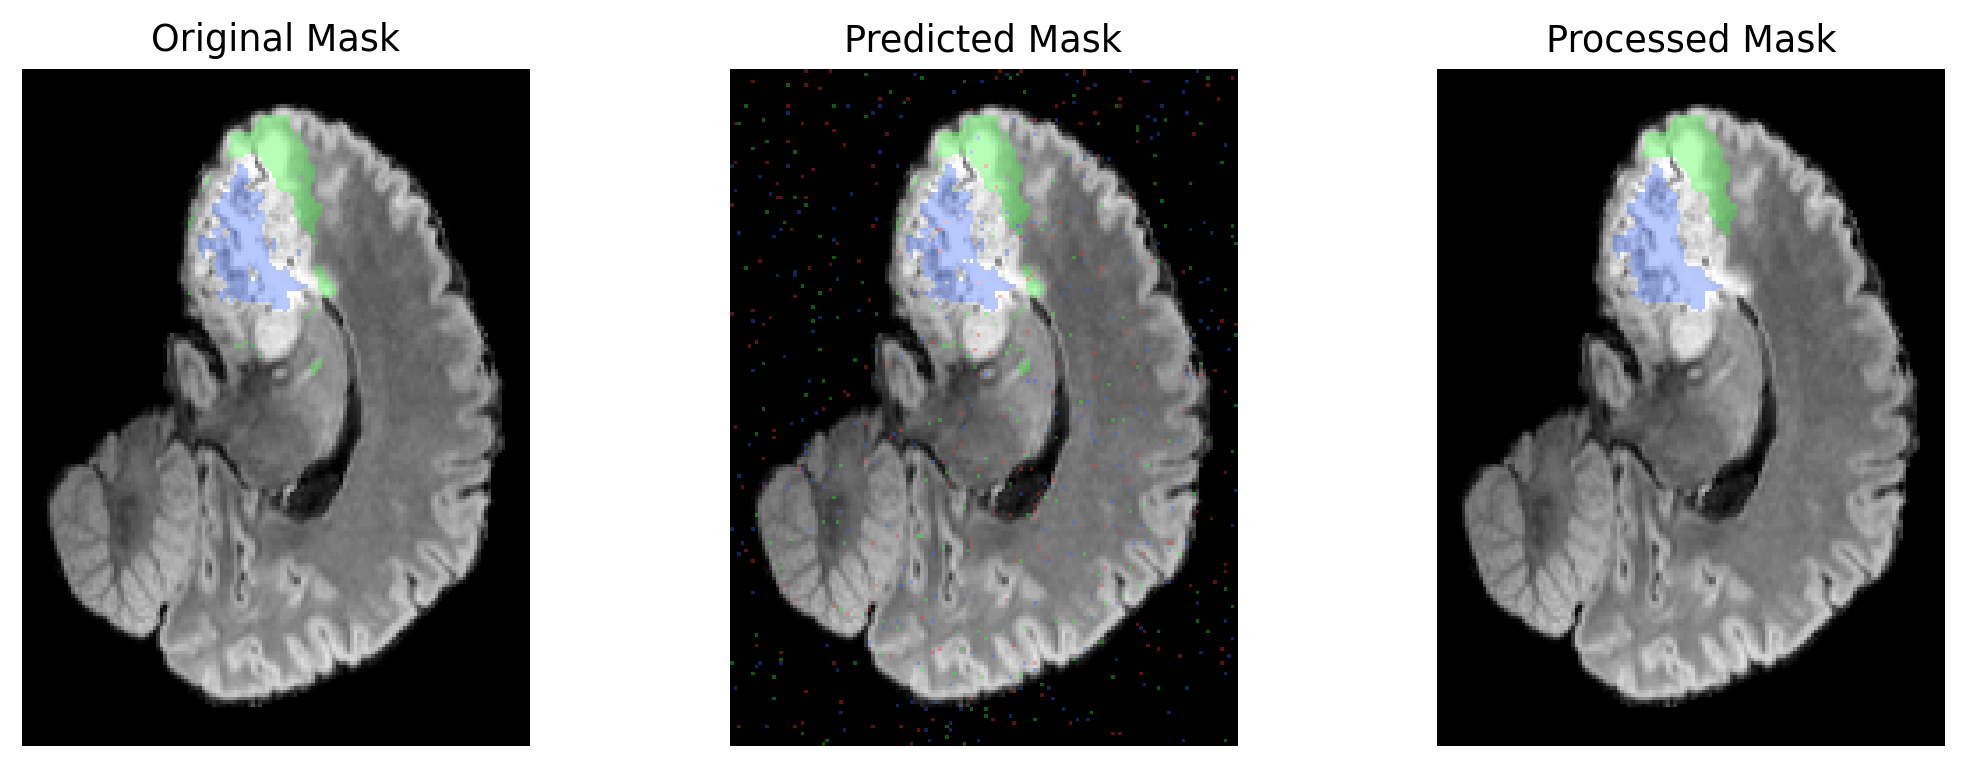

Saved to: /content/brats2021_training_process.png


In [ ]:
png = make_training_process_figure(save_path="/content/brats2021_training_process.png", pick_slice="max")
from IPython.display import Image, display
display(Image(png))
print("Saved to:", png)


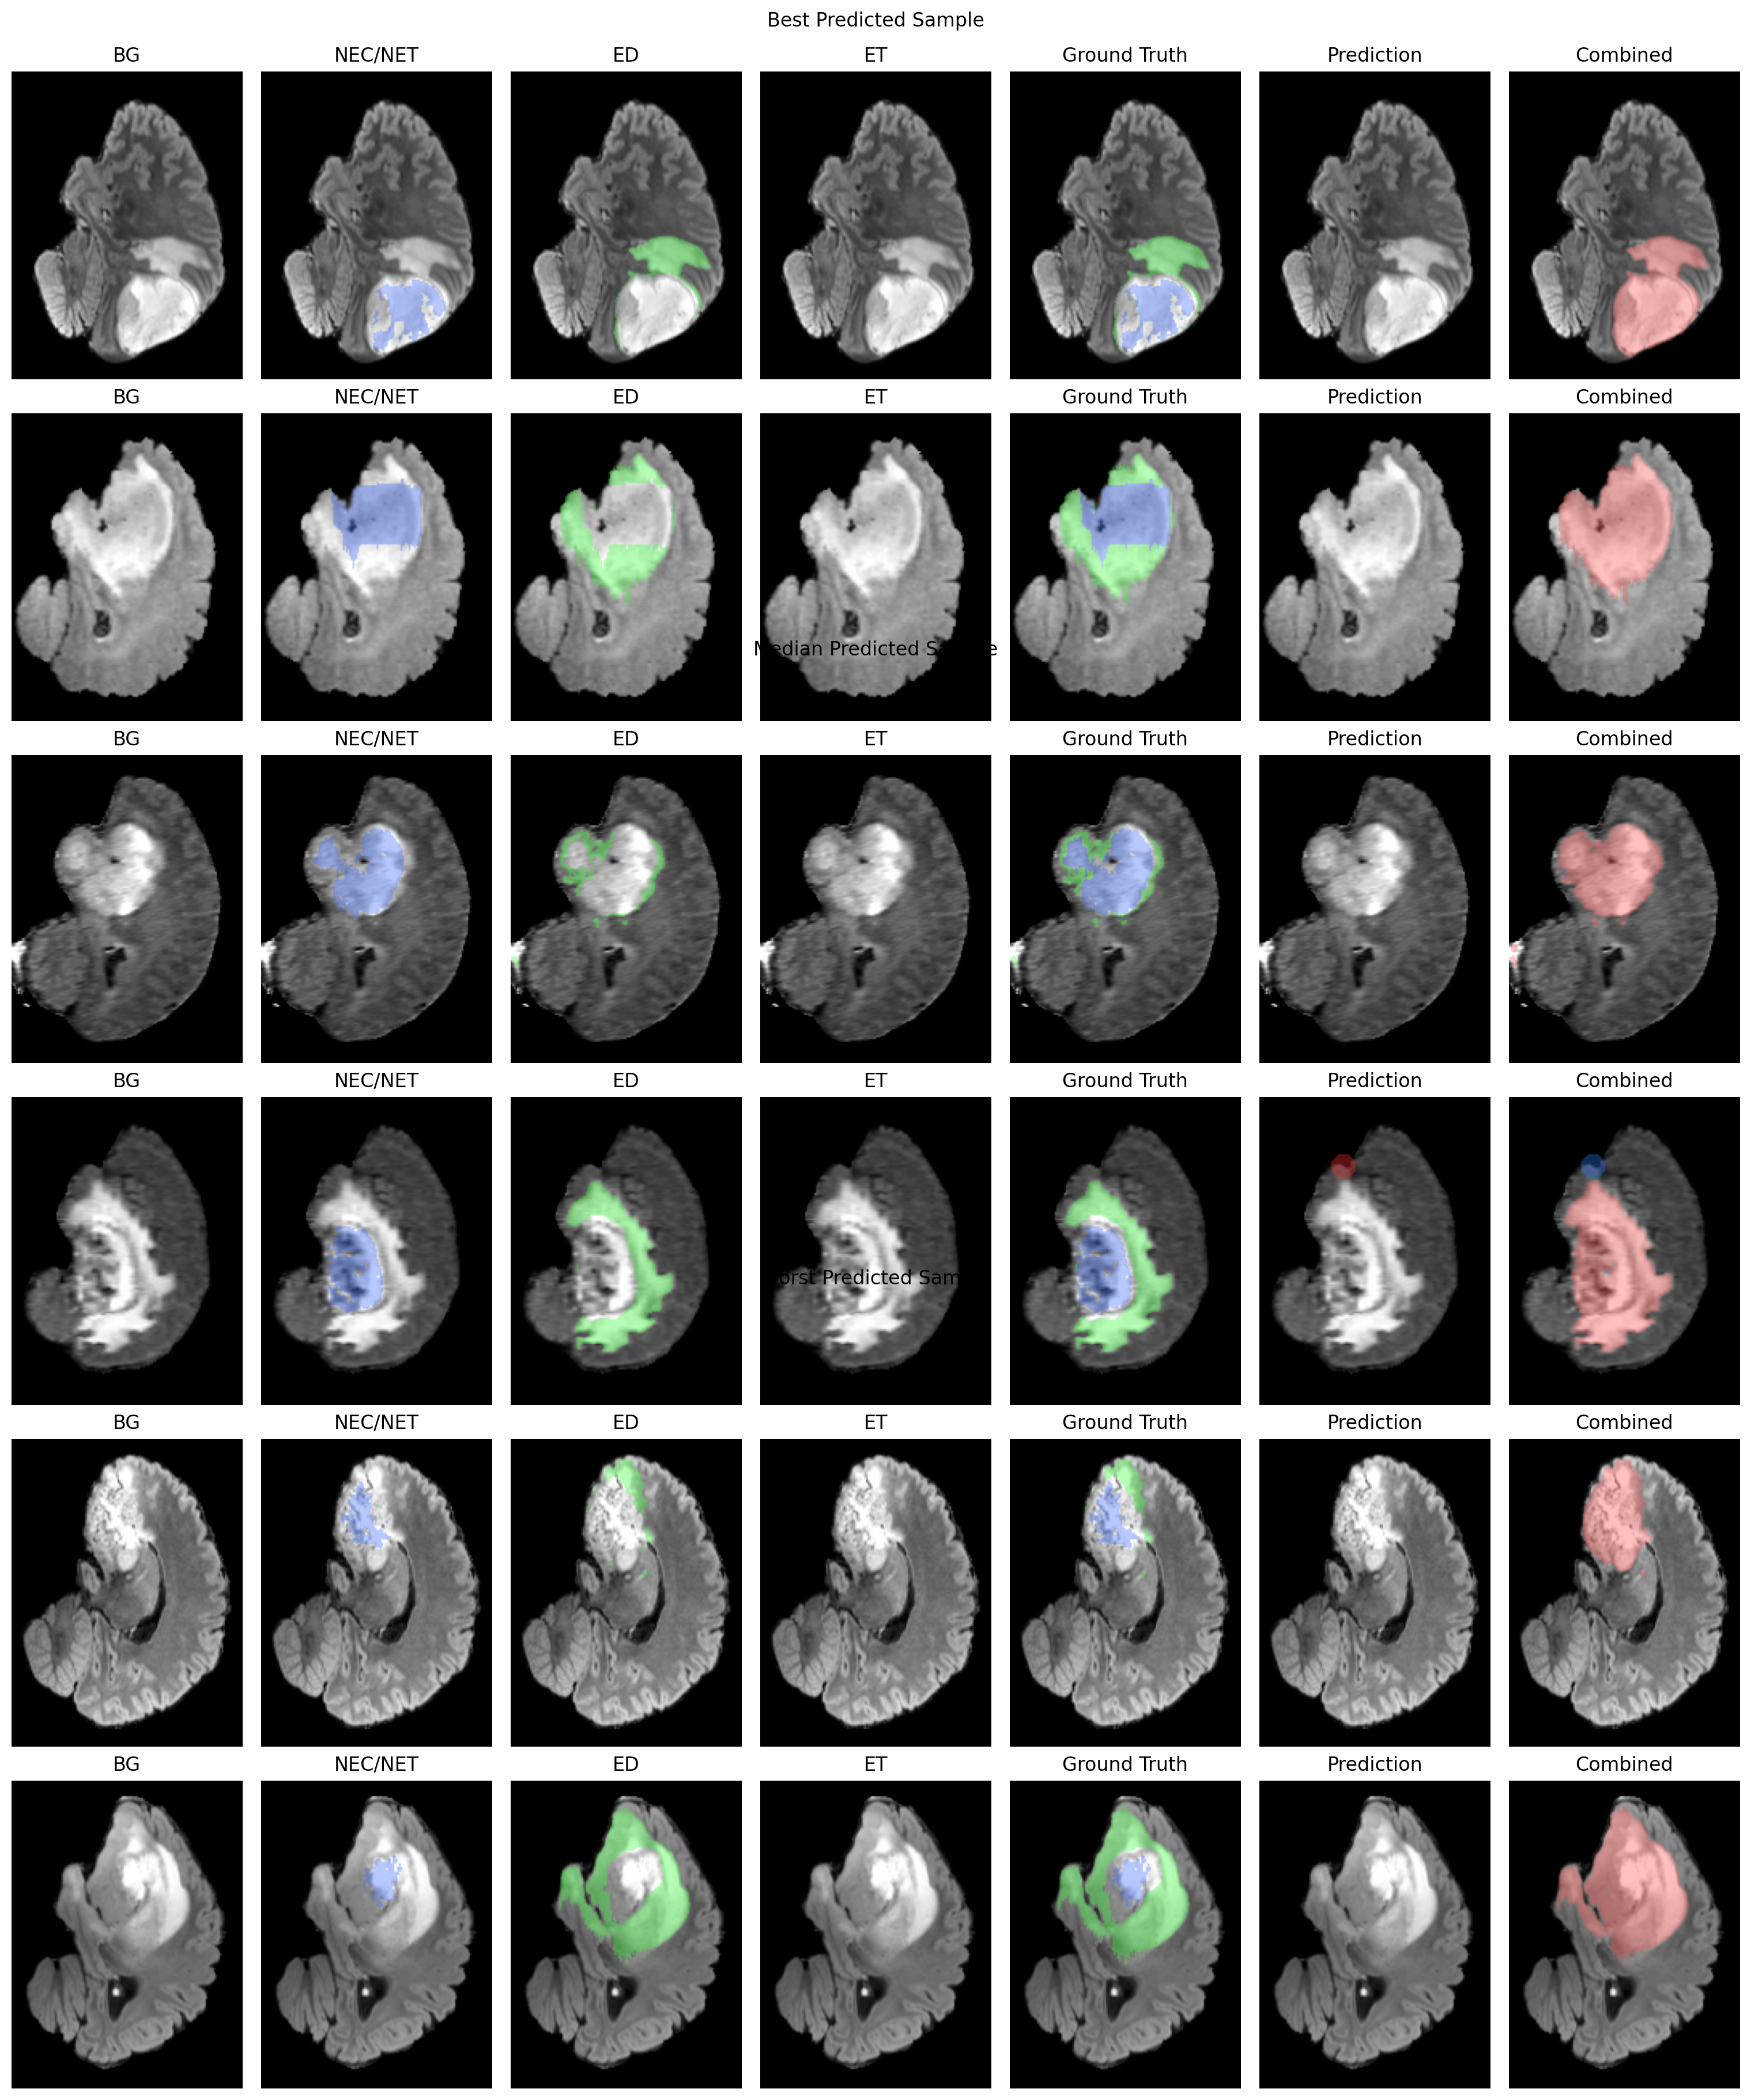

Saved to: /content/brats2021_bmw.png


In [ ]:
# ================== LOW-RAM BMW FIGURE FOR BRATS ==================
# Output: /content/brats2021_bmw.png

!pip -q install scipy

import os, glob, numpy as np, matplotlib.pyplot as plt, gc
from scipy.ndimage import label as cc_label, generate_binary_structure

# -------- CONFIG (ubah sesuai kebutuhan) --------
os.environ.setdefault("BRATS2021_OUT", "/content/brats2021_processed")  # folder *.npz
# os.environ["WEIGHTS"] = "/content/checkpoints/best.pt"               # optional
OUT_PATH      = "/content/brats2021_bmw.png"
K_PER_GROUP   = 2          # baris per grup
PATCH, STRIDE = 128, 96    # samakan dengan modelmu
USE_FP16      = True       # inference hemat memori
MAX_CASES     = 0          # 0 = pakai semua; >0 = batasi jumlah kasus untuk scanning

# -------- LOCATE DATA --------
def find_npz_root():
    cands = [
        os.environ.get("BRATS2021_OUT",""),
        os.environ.get("BRATS_OUT",""),
        "/content/brats2021_processed", "/content/brats_processed",
        "/mnt/data/brats2021_processed", "/mnt/data/brats_processed",
    ]
    for r in cands:
        if not r: continue
        ps = sorted(glob.glob(os.path.join(r, "*.npz")))
        if ps: return r, ps
    return None, []

# -------- UTILS (ringan) --------
COLOR_NCR = np.array([0.20,0.40,1.00])
COLOR_ED  = np.array([0.20,1.00,0.20])
COLOR_ET  = np.array([1.00,0.20,0.20])
ALPHA     = 0.35

def norm01(x):
    x = x.astype(np.float32)
    return (x - x.min()) / (x.max() - x.min() + 1e-6)

def overlay_rgb(bg, masks):
    rgb = np.stack([bg,bg,bg], axis=-1).copy()
    for m, color in masks:
        m = m.astype(bool)
        rgb[m] = (1-ALPHA)*rgb[m] + ALPHA*color
    return rgb

def dice_bin(y_true, y_pred):
    inter = (y_true & y_pred).sum()
    denom = y_true.sum() + y_pred.sum()
    return (2.0 * inter / max(1, denom)).item()

def dice_macro_3(gt, pr):
    return float(np.mean([dice_bin(gt==c, pr==c) for c in (1,2,3)]))

def best_tumor_slice(mask3d):
    areas = [(mask3d[z]>0).sum() for z in range(mask3d.shape[0])]
    return int(np.argmax(areas)) if max(areas)>0 else mask3d.shape[0]//2

# -------- MODEL INFERENCE (hemat memori) --------
def try_model_predict(img, patch=128, stride=96):
    """
    img: (C,D,H,W) float32
    return: (D,H,W) uint8 di {0,1,2,3}
    """
    try:
        import torch
        from infer_visualize import load_trained_model, sliding_window_predict  # sesuaikan modulmu
        DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        weights = os.environ.get("WEIGHTS","")
        model   = load_trained_model(weights).to(DEVICE).eval()

        with torch.no_grad():
            x = torch.from_numpy(img[None,...])  # (1,C,D,H,W)
            if USE_FP16 and torch.cuda.is_available():
                with torch.cuda.amp.autocast(dtype=torch.float16):
                    x = x.to(DEVICE, non_blocking=True)
                    logits = sliding_window_predict(model, x, patch=patch, stride=stride)  # (1,4,D,H,W) on CPU
            else:
                x = x.to(DEVICE, non_blocking=True)
                logits = sliding_window_predict(model, x, patch=patch, stride=stride)

        pred = np.argmax(logits.numpy(), axis=1).squeeze(0).astype(np.uint8)

        # bersihkan
        del model, x, logits
        if 'torch' in globals():
            torch.cuda.empty_cache()
        gc.collect()
        return pred
    except Exception as e:
        # fallback simulasi (agar layout tetap jadi)
        rng = np.random.default_rng(123)
        lbl_shape = img.shape[1:]  # (D,H,W)
        pred = np.zeros(lbl_shape, dtype=np.uint8)
        # bikin dummy blob kecil per kelas
        D,H,W = lbl_shape
        for cls, r in zip([1,2,3],[10,12,8]):
            z = rng.integers(0, D); cy = rng.integers(r+5, H-r-5); cx = rng.integers(r+5, W-r-5)
            zz, yy, xx = np.ogrid[:D,:H,:W]
            mask = (zz-z)**2 + (yy-cy)**2 + (xx-cx)**2 <= r*r
            pred[mask] = cls
        return pred

# ================= PASS 1: SCAN & SCORE TANPA SIMPAN VOLUME =================
root, paths = find_npz_root()
assert paths, "NPZ tidak ditemukan. Set os.environ['BRATS2021_OUT'] ke folder NPZ kamu."

if MAX_CASES and MAX_CASES > 0:
    paths = paths[:MAX_CASES]

scores = []   # hanya [(score, path, z)]
for p in paths:
    d   = np.load(p, allow_pickle=False)
    lbl = d["label"].astype(np.uint8)    # (D,H,W) => kecil (<= ~9MB), aman
    z   = best_tumor_slice(lbl)

    # prediksi (model jalan sekali per kasus), langsung buang setelah dipakai
    img = d["image"].astype(np.float32)  # (C,D,H,W)
    pred= try_model_predict(img, patch=PATCH, stride=STRIDE)
    score = dice_macro_3(lbl, pred)

    scores.append((score, p, z))
    # bebasin memori
    del d, img, lbl, pred
    gc.collect()

# tentukan best/median/worst (pakai hanya metadata kecil)
scores.sort(key=lambda x: x[0])
n = len(scores)
best   = scores[-K_PER_GROUP:]
median = scores[max(0, n//2 - K_PER_GROUP//2): max(0, n//2 - K_PER_GROUP//2)+K_PER_GROUP]
worst  = scores[:K_PER_GROUP]

groups = [("Best Predicted Sample", best[::-1]),
          ("Median Predicted Sample", median),
          ("Worst Predicted Sample", worst)]

# ================= PASS 2: RENDER HANYA KASUS TERPILIH =================
COLS = 7
ROWS = sum(len(g[1]) for g in groups)
fig_w, fig_h = 2.2*COLS, 3.0*ROWS
fig, axes = plt.subplots(ROWS, COLS, figsize=(fig_w, fig_h))
if ROWS == 1: axes = np.expand_dims(axes, 0)

row = 0
for title, group in groups:
    fig.text(0.5, 1.0 - (row/(ROWS+0.6)), title, ha="center", va="bottom", fontsize=12)
    for score, p, z in group:
        d    = np.load(p, allow_pickle=False)
        img  = d["image"].astype(np.float32)
        lbl  = d["label"].astype(np.uint8)
        flair= img[3]
        pred = try_model_predict(img, patch=PATCH, stride=STRIDE)

        bg   = norm01(flair[z])
        gt2d = lbl[z]; pr2d = pred[z]

        # kolom 0: BG
        axes[row,0].imshow(bg, cmap="gray"); axes[row,0].set_title("BG"); axes[row,0].axis("off")
        # kolom 1..3: GT per kelas
        axes[row,1].imshow(overlay_rgb(bg, [(gt2d==1, COLOR_NCR)])); axes[row,1].set_title("NEC/NET"); axes[row,1].axis("off")
        axes[row,2].imshow(overlay_rgb(bg, [(gt2d==2, COLOR_ED)]));  axes[row,2].set_title("ED");      axes[row,2].axis("off")
        axes[row,3].imshow(overlay_rgb(bg, [(gt2d==3, COLOR_ET)]));  axes[row,3].set_title("ET");      axes[row,3].axis("off")
        # kolom 4: GT all
        axes[row,4].imshow(overlay_rgb(bg, [(gt2d==1,COLOR_NCR),(gt2d==2,COLOR_ED),(gt2d==3,COLOR_ET)]))
        axes[row,4].set_title("Ground Truth"); axes[row,4].axis("off")
        # kolom 5: Pred all
        axes[row,5].imshow(overlay_rgb(bg, [(pr2d==1,COLOR_NCR),(pr2d==2,COLOR_ED),(pr2d==3,COLOR_ET)]))
        axes[row,5].set_title("Prediction"); axes[row,5].axis("off")
        # kolom 6: Combined TP/FP/FN
        gt_bin, pr_bin = gt2d>0, pr2d>0
        tp = gt_bin & pr_bin; fn = gt_bin & (~pr_bin); fp = (~gt_bin) & pr_bin
        comb = np.stack([bg,bg,bg], axis=-1).copy()
        comb[tp] = (1-ALPHA)*comb[tp] + ALPHA*np.array([0.20,1.00,0.20])
        comb[fn] = (1-ALPHA)*comb[fn] + ALPHA*np.array([1.00,0.30,0.30])
        comb[fp] = (1-ALPHA)*comb[fp] + ALPHA*np.array([0.20,0.50,1.00])
        axes[row,6].imshow(comb); axes[row,6].set_title("Combined"); axes[row,6].axis("off")

        # bebasin memori secepatnya
        del d, img, lbl, pred, flair, gt2d, pr2d, bg, comb
        gc.collect()
        row += 1

plt.tight_layout(h_pad=0.8, w_pad=0.4)
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
plt.savefig(OUT_PATH, dpi=200, bbox_inches="tight"); plt.close(fig)

from IPython.display import Image, display
display(Image(OUT_PATH))
print("Saved to:", OUT_PATH)
# ================================================================
